#  FoodTech — Analyzing Food Delivery Demand Across Regions
### Data Science Capstone | Project Topic 8

This notebook is organised strictly around the **5 Expanded Business Objectives** and **20 Business
Questions** defined in Phase 3, so that every code block maps to exactly one question and one
testable hypothesis. Each question section states the **Hypothesis (H₀ / H₁)**, runs the matched
**statistical test**, and renders the matched **chart type**, so the notebook, the question list, and the
statistical plan are fully aligned.

| Objective | Focus |
|---|---|
| 1 | Regional Demand & Market Expansion Potential |
| 2 | Customer Behavior, Segmentation & Loyalty |
| 3 | Delivery Partner & Logistics Efficiency |
| 4 | Restaurant Performance & Operational Capacity |
| 5 | Order Economics, Discounts & Profitability Risk |


##  Environment Setup & Library Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px

from scipy import stats
from scipy.stats import pearsonr, ttest_ind, chi2_contingency, f_oneway, kurtosis, skew

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='Set2')
plt.rcParams['figure.figsize'] = (9, 5.5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'


## 1. Data Loading

In [ ]:
orders      = pd.read_excel('Orders_Cleaned.xlsx', sheet_name='Orders_Data')
customers   = pd.read_excel('Customers_Cleaned.xlsx')
partners    = pd.read_excel('Delivery_Partners_Cleaned.xlsx')
restaurants = pd.read_excel('Restaurant_Cleaned.xlsx')

for name, df in [('Orders', orders), ('Customers', customers),
                  ('Delivery Partners', partners), ('Restaurants', restaurants)]:
    print(f'{name:20s} -> {df.shape[0]:>7,} rows x {df.shape[1]} columns')


Orders               -> 100,000 rows x 23 columns
Customers            ->  22,000 rows x 10 columns
Delivery Partners    ->   1,100 rows x 10 columns
Restaurants          ->     550 rows x 8 columns


## 2. Feature Engineering & Master Dataset

`Orders.Region` carries a typo (*"Metropolitian"*) which is standardised. `Customers.City` and
`Restaurants.City` actually hold the **region tier** (Urban / Semi-Urban / Metropolitan), not a real
city name, so they are renamed to `Region` for consistency, then everything is merged into one
`master` analytical table keyed on `Order_ID`.

In [ ]:
orders['Region'] = orders['Region'].replace({'Metropolitian': 'Metropolitan'})
orders['Order_Date']  = pd.to_datetime(orders['Order_Date'])
orders['Year']        = orders['Order_Date'].dt.year
orders['Month_Year']  = orders['Order_Date'].dt.to_period('M').astype(str)

customers = customers.rename(columns={'Customer_Id': 'Customer_ID', 'City': 'Region'})
restaurants_r = restaurants.rename(columns={'City': 'Rest_Region'})

master = (orders
          .merge(customers, on='Customer_ID', how='left', suffixes=('', '_cust'))
          .merge(restaurants_r, on='Restaurant_ID', how='left', suffixes=('', '_rest'))
          .merge(partners, on='Delivery_Partner_ID', how='left', suffixes=('', '_partner')))

print('Master shape:', master.shape)
master.head(3)


Master shape: (100000, 50)


,Row_ID,Order_ID,Order_Date,Customer_ID,Restaurant_ID,Region,Delivery_Partner_ID,Order_Value,Delivery_Fee,Discount_Applied,...,Low_Capacity_Flag,Partner_Name,Vehicle_Type,Avg_Delivery_Speed_KMPH,Successful_Deliveries,Delayed_Deliveries,Avg_Customer_Rating,Region_partner,Delivery_Efficiency_Score,Status
0,ORD-000001,O107233,2023-01-01,C01416,R205,Metropolitan,D0972,433,50,75,...,No,Kiran Chopra,Car,22.43,32,2,4.69,Metropolitan,0.826,Active
1,ORD-000002,O120815,2023-01-01,C04406,R468,Semi-Urban,D0462,503,35,0,...,Yes,Arjun Singh,Car,8.11,0,1,4.30,Semi-Urban,0.319,Inactive/New
2,ORD-000003,O129345,2023-01-01,C14100,R363,Metropolitan,D0175,232,40,0,...,Yes,Ravi Singh,Scooter,27.74,10,0,4.63,Metropolitan,0.886,Active


## 3. Descriptive Statistics — Central Tendency, Spread, Skewness & Kurtosis

Profiling the core numeric variables before drilling into the 20 objective-based questions.
**Kurtosis** flags fat-tailed / outlier-heavy variables (leptokurtic > 0); **skewness** flags
asymmetry — both feed directly into which statistical test (parametric vs non-parametric) is
appropriate later.

In [ ]:
numeric_cols = ['Order_Value', 'Delivery_Fee', 'Discount_Applied', 'Final_Amount',
                'Net_Revenue', 'Delivery_Time_Minutes', 'Order_Rating']

desc = master[numeric_cols].describe().T
desc['skewness'] = [skew(master[c].dropna()) for c in numeric_cols]
desc['kurtosis'] = [kurtosis(master[c].dropna()) for c in numeric_cols]
desc.round(2)


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Order_Value,100000.0,545.68,167.17,200.0,429.0,542.0,656.0,1200.0,0.22,-0.07
Delivery_Fee,100000.0,35.69,6.17,30.0,30.0,35.0,40.0,55.0,1.11,0.49
Discount_Applied,100000.0,21.41,40.66,0.0,0.0,0.0,30.0,150.0,1.99,2.95
Final_Amount,100000.0,559.95,172.10,80.0,441.0,557.0,673.0,1250.0,0.18,-0.06
Net_Revenue,100000.0,520.63,218.74,0.0,409.0,540.0,663.0,1250.0,-0.55,0.45
Delivery_Time_Minutes,100000.0,35.51,4.91,25.0,32.0,35.0,39.0,50.0,0.09,-0.27
Order_Rating,100000.0,4.02,0.93,1.0,4.0,4.0,5.0,5.0,-1.02,1.00


---
# SECTION A — Objective 1: Regional Demand & Market Expansion Potential
Identify which regions generate the highest order volume, revenue, and growth momentum to
prioritize expansion.

### Q1. Which regions generate the highest total order volume and revenue? *(Univariate — Bar, Pie & Geo Map)*
**H0:** Mean Net_Revenue per order is equal across all three regions.
**H1:** Mean Net_Revenue per order differs across at least one region. *(two-tailed, tested in Q2)*

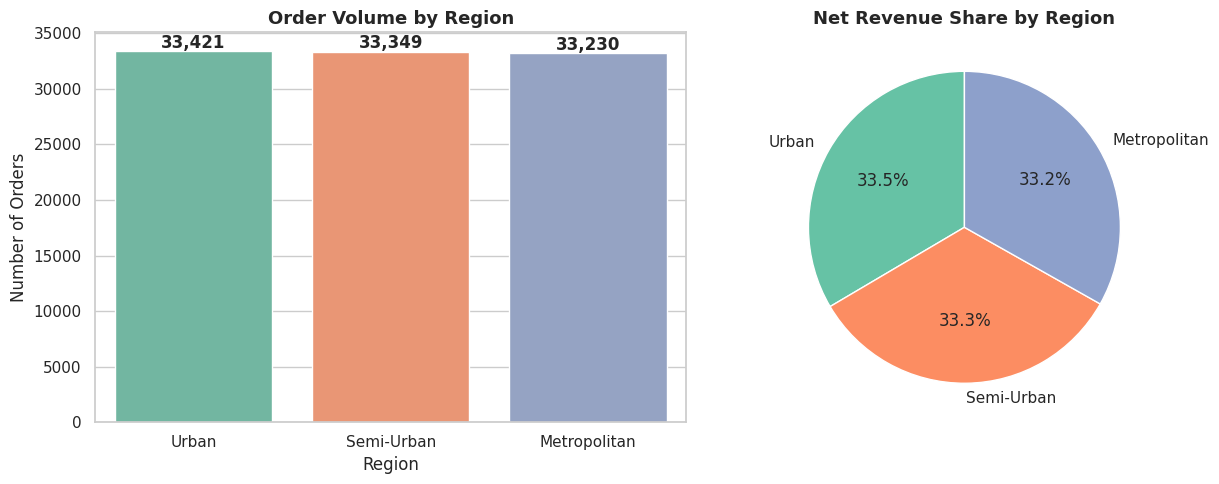

Region
Urban           17434107
Semi-Urban      17355192
Metropolitan    17273586
Name: Net_Revenue, dtype: int64

In [ ]:
region_counts  = master['Region'].value_counts()
region_revenue = master.groupby('Region')['Net_Revenue'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=region_counts.index, y=region_counts.values, ax=axes[0], palette='Set2')
axes[0].set_title('Order Volume by Region'); axes[0].set_ylabel('Number of Orders')
for i, v in enumerate(region_counts.values):
    axes[0].text(i, v + 300, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(region_revenue.values, labels=region_revenue.index, autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette('Set2'), wedgeprops={'edgecolor': 'white'})
axes[1].set_title('Net Revenue Share by Region')
plt.tight_layout(); plt.show()

region_revenue.round(0)


### Q2. How does average order value differ across regions? 
**H0:** Mean Final_Amount is equal across Urban, Semi-Urban and Metropolitan regions.
**H1:** Mean Final_Amount differs across at least one region. *(two-tailed)*

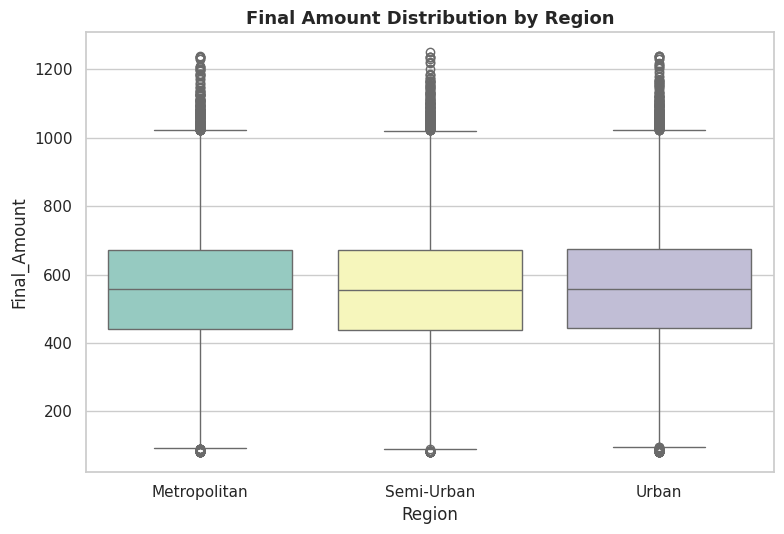

One-way ANOVA: F = 1.053, p = 0.3488
Conclusion: Fail to reject H0 — no significant regional difference in order value.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.boxplot(data=master, x='Region', y='Final_Amount', palette='Set3', ax=ax)
ax.set_title('Final Amount Distribution by Region'); plt.tight_layout(); plt.show()

groups = [g['Final_Amount'].dropna().values for _, g in master.groupby('Region')]
f_stat, p_val = f_oneway(*groups)
print(f'One-way ANOVA: F = {f_stat:.3f}, p = {p_val:.4g}')
print('Conclusion:', 'Reject H0 — average order value differs by region.' if p_val < 0.05
      else 'Fail to reject H0 — no significant regional difference in order value.')


### Q3. Which regions show the strongest repeat-order growth potential? 
**H0:** There is no upward month-over-month growth trend in order volume within any region (slope = 0).
**H1:** At least one region shows a significant positive growth trend over time (slope > 0). *(one-tailed)*

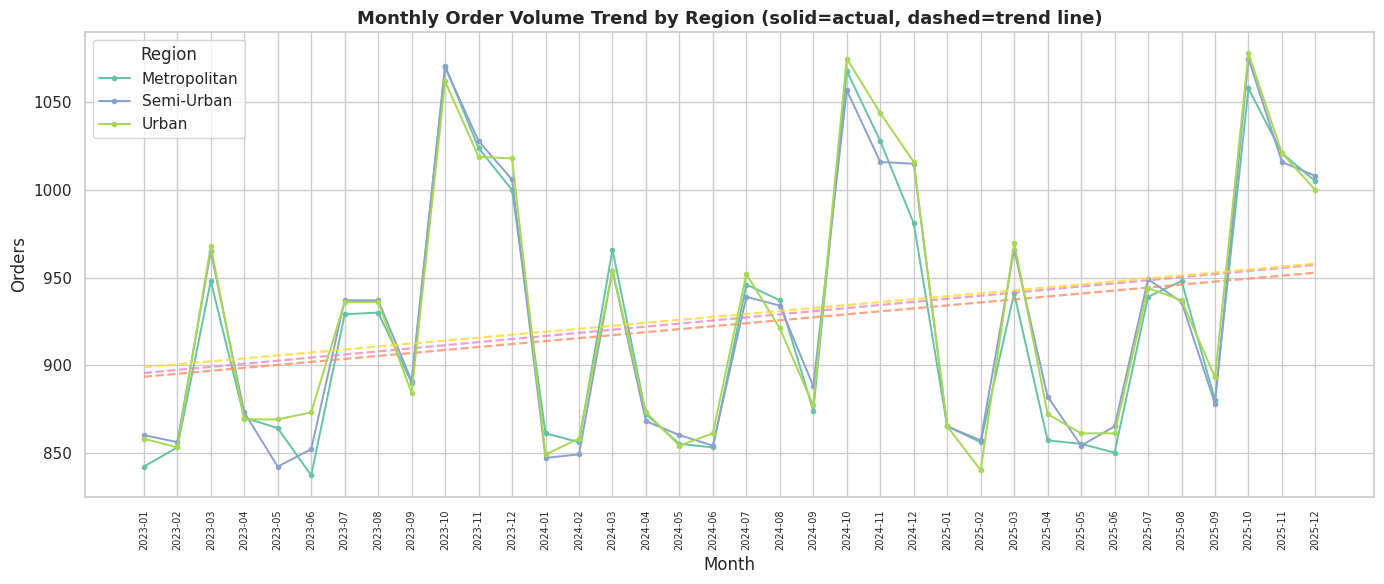

Metropolitan    slope=+1.70 orders/month, p=0.1487 -> no significant growth
Semi-Urban      slope=+1.77 orders/month, p=0.1338 -> no significant growth
Urban           slope=+1.69 orders/month, p=0.1587 -> no significant growth


In [ ]:
region_month = master.groupby(['Month_Year', 'Region']).size().unstack('Region').sort_index()

plt.figure(figsize=(14, 6))
for region in region_month.columns:
    y = region_month[region].values
    x = np.arange(len(y))
    plt.plot(region_month.index, y, marker='o', markersize=3, linewidth=1.4, label=region)
    trend = np.poly1d(np.polyfit(x, y, 1))(x)
    plt.plot(region_month.index, trend, linestyle='--', linewidth=1.6, alpha=0.8)
plt.title('Monthly Order Volume Trend by Region (solid=actual, dashed=trend line)')
plt.xlabel('Month'); plt.ylabel('Orders'); plt.xticks(rotation=90, fontsize=7)
plt.legend(title='Region'); plt.tight_layout(); plt.show()

for region in region_month.columns:
    y = region_month[region].values; x = np.arange(len(y))
    slope, intercept, r, p, se = stats.linregress(x, y)
    print(f'{region:15s} slope={slope:+.2f} orders/month, p={p:.4g} ->',
          'significant growth' if (p < 0.05 and slope > 0) else 'no significant growth')


### Q4. Does order demand spike differently by region during festival periods? 
**H0:** Mean daily order volume during Festival_Flag=True equals non-festival days, for each region.
**H1:** Mean daily order volume during Festival_Flag=True is greater than non-festival days. *(one-tailed, right)*

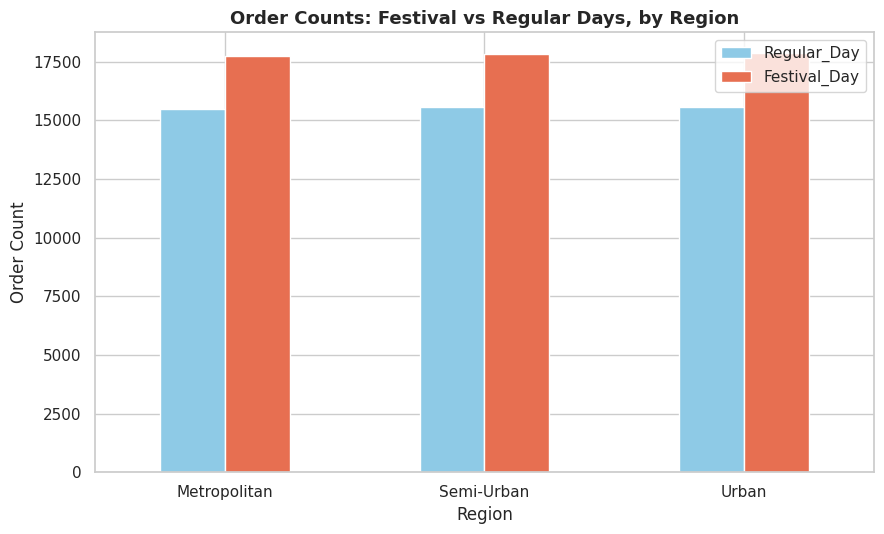

,Regular_Day,Festival_Day
Region,,
Metropolitan,15490,17740
Semi-Urban,15541,17808
Urban,15570,17851


Metropolitan    t=+9.96, one-tailed p=1e-22 -> significant festival uplift
Semi-Urban      t=+9.90, one-tailed p=1.731e-22 -> significant festival uplift
Urban           t=+10.40, one-tailed p=1.55e-24 -> significant festival uplift


In [ ]:
fest_region = master.groupby(['Region', 'Festival_Flag']).size().unstack('Festival_Flag')
fest_region.columns = ['Regular_Day', 'Festival_Day']
fest_region.plot(kind='bar', figsize=(9, 5.5), color=['#8ecae6', '#e76f51'])
plt.title('Order Counts: Festival vs Regular Days, by Region')
plt.ylabel('Order Count'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(fest_region)

for region in master['Region'].unique():
    sub = master[master['Region'] == region]
    daily_fest = sub[sub['Festival_Flag'] == True].groupby(sub['Order_Date'].dt.date).size()
    daily_reg  = sub[sub['Festival_Flag'] == False].groupby(sub['Order_Date'].dt.date).size()
    t_stat, p_val = ttest_ind(daily_fest, daily_reg, equal_var=False)
    p_one = p_val / 2 if t_stat > 0 else 1 - p_val / 2
    print(f'{region:15s} t={t_stat:+.2f}, one-tailed p={p_one:.4g} ->',
          'significant festival uplift' if p_one < 0.05 else 'no significant uplift')


### 📊 Objective 1 Dashboard 

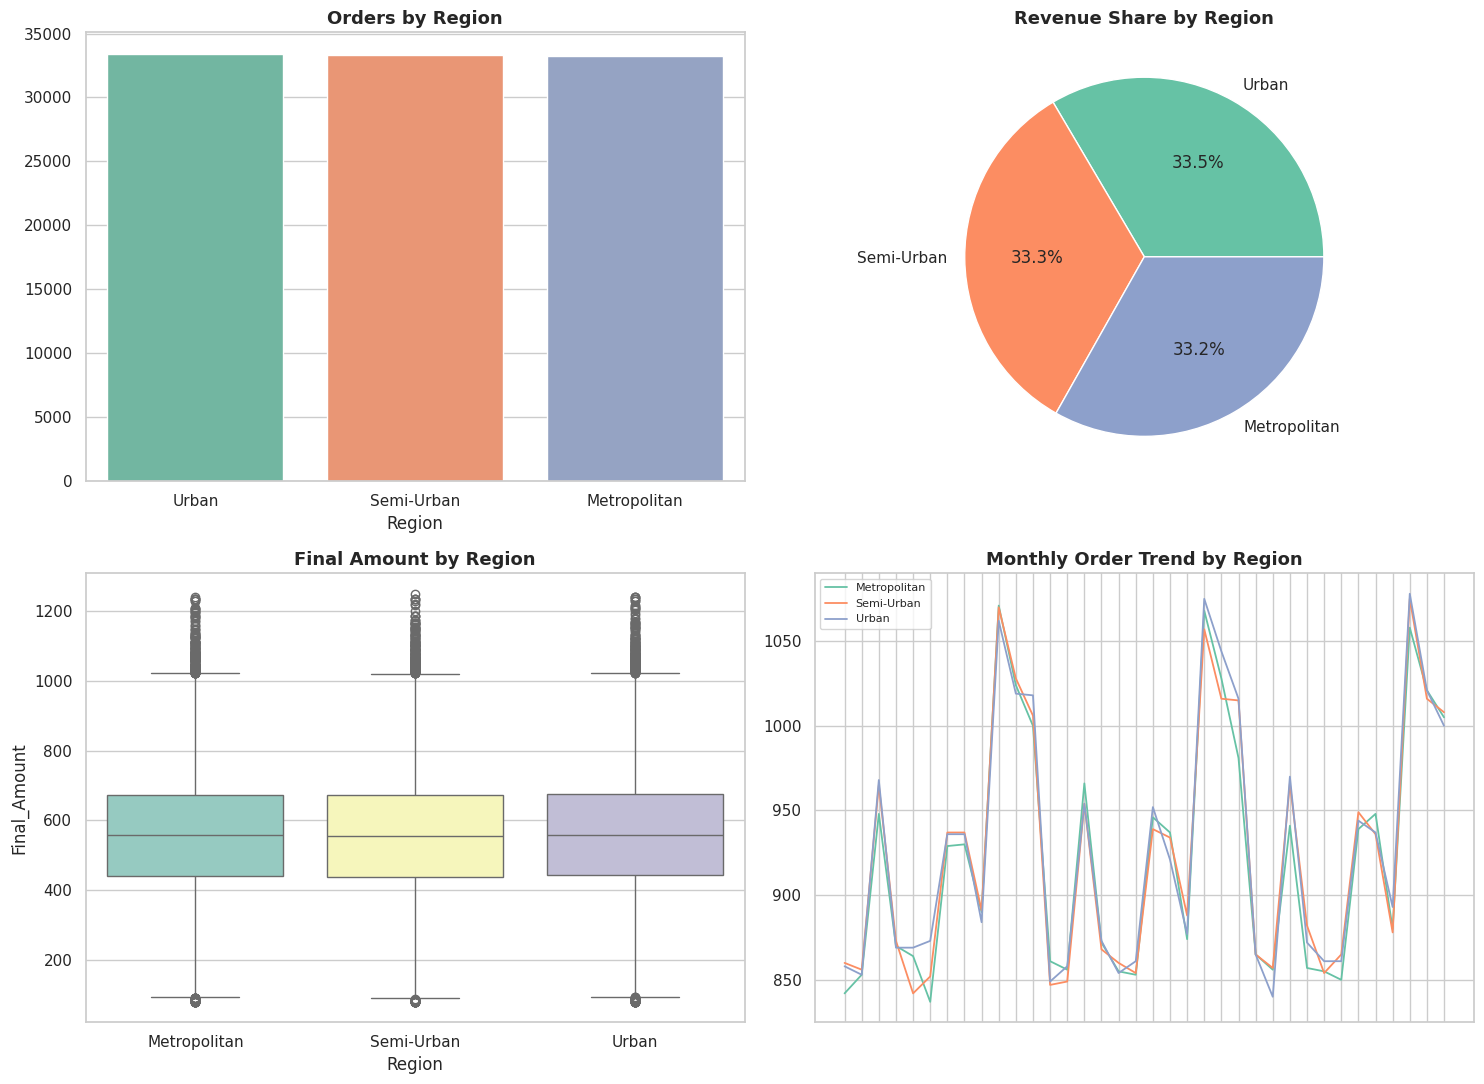

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.barplot(x=region_counts.index, y=region_counts.values, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Orders by Region')

axes[0, 1].pie(region_revenue.values, labels=region_revenue.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'))
axes[0, 1].set_title('Revenue Share by Region')

sns.boxplot(data=master, x='Region', y='Final_Amount', palette='Set3', ax=axes[1, 0])
axes[1, 0].set_title('Final Amount by Region')

for region in region_month.columns:
    axes[1, 1].plot(region_month.index, region_month[region], linewidth=1.3, label=region)
axes[1, 1].set_title('Monthly Order Trend by Region'); axes[1, 1].set_xticklabels([]); axes[1, 1].legend(fontsize=8)

plt.tight_layout(); plt.show()


---
# SECTION B — Objective 2: Customer Behavior, Segmentation & Loyalty
Understand how customer type, demographics, and cuisine preference drive spend and retention.

### Q5. How does Average_Spend differ across Customer_Type? 
**H0:** Mean Average_Spend is equal across New, Returning and Loyal customers.
**H1:** Mean Average_Spend differs across at least one Customer_Type (expected Loyal > Returning > New). *(one-tailed)*

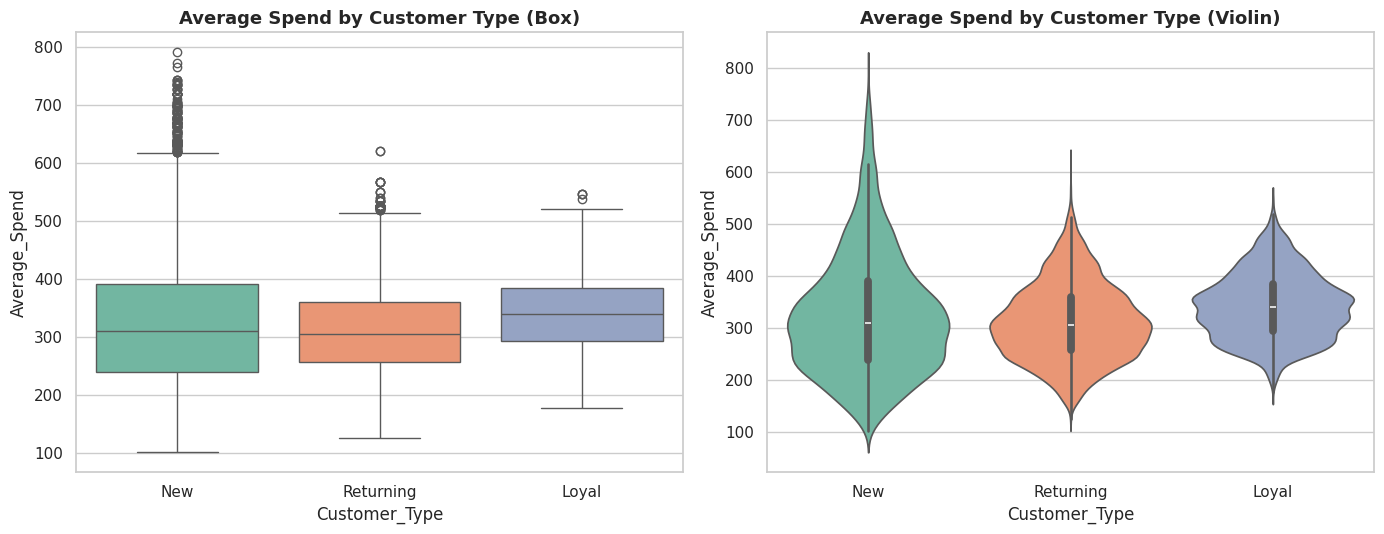

One-way ANOVA: F = 199.798, p = 1.018e-86
Customer_Type
Loyal        342.88
New          326.66
Returning    312.53
Name: Average_Spend, dtype: float64
Conclusion: Reject H0 — spend differs significantly by customer type.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=customers, x='Customer_Type', y='Average_Spend', palette='Set2', ax=axes[0])
axes[0].set_title('Average Spend by Customer Type (Box)')
sns.violinplot(data=customers, x='Customer_Type', y='Average_Spend', palette='Set2', ax=axes[1])
axes[1].set_title('Average Spend by Customer Type (Violin)')
plt.tight_layout(); plt.show()

groups = [g['Average_Spend'].values for _, g in customers.groupby('Customer_Type')]
f_stat, p_val = f_oneway(*groups)
means = customers.groupby('Customer_Type')['Average_Spend'].mean().sort_values(ascending=False)
print(f'One-way ANOVA: F = {f_stat:.3f}, p = {p_val:.4g}')
print(means.round(2))
print('Conclusion:', 'Reject H0 — spend differs significantly by customer type.' if p_val < 0.05 else 'Fail to reject H0.')


### Q6. Which cuisines are most associated with Loyal vs New customers?
**H0:** Preferred_Cuisine is independent of Customer_Type.
**H1:** Preferred_Cuisine is associated with Customer_Type. *(two-tailed)*

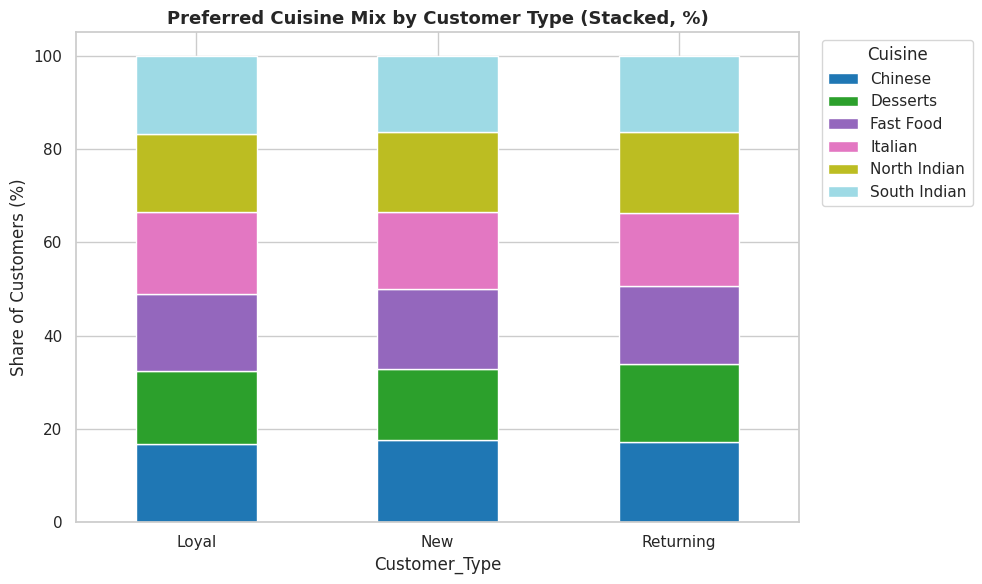

Chi-square = 16.23, dof = 10, p = 0.09321
Conclusion: Fail to reject H0.


In [ ]:
ct = pd.crosstab(customers['Customer_Type'], customers['Preferred_Cuisine'])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Preferred Cuisine Mix by Customer Type (Stacked, %)')
plt.ylabel('Share of Customers (%)'); plt.xticks(rotation=0)
plt.legend(title='Cuisine', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

chi2, p, dof, exp = chi2_contingency(ct)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4g}')
print('Conclusion:', 'Reject H0 — cuisine preference is associated with customer type.' if p < 0.05 else 'Fail to reject H0.')


### Q7. Does Total_Orders correlate with Average_Spend? 
**H0:** No significant linear correlation between Total_Orders and Average_Spend (rho = 0).
**H1:** A significant positive correlation exists (rho > 0). *(one-tailed, right)*

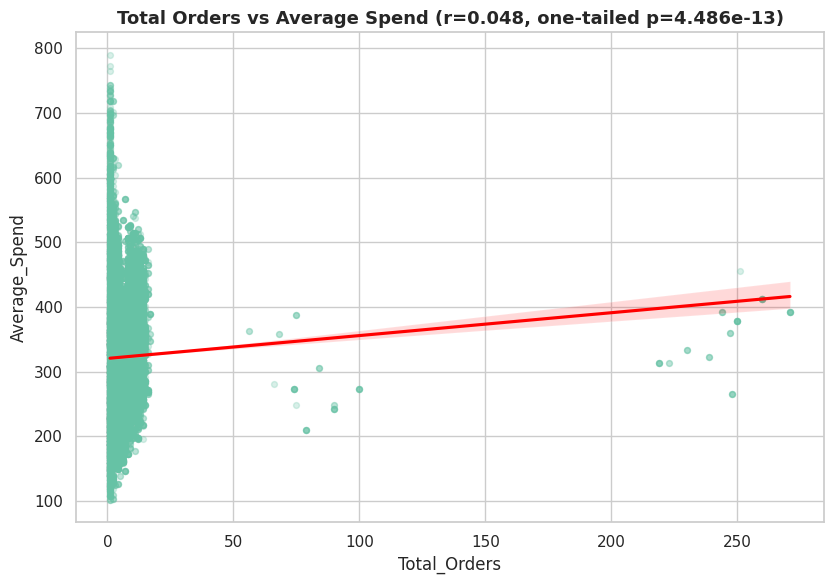

Conclusion: Reject H0 — significant positive correlation.


In [ ]:
r, p = pearsonr(customers['Total_Orders'], customers['Average_Spend'])
p_one = p / 2 if r > 0 else 1 - p / 2

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.regplot(data=customers, x='Total_Orders', y='Average_Spend',
            scatter_kws={'alpha': 0.25, 's': 18}, line_kws={'color': 'red'}, ax=ax)
ax.set_title(f'Total Orders vs Average Spend (r={r:.3f}, one-tailed p={p_one:.4g})')
plt.tight_layout(); plt.show()
print('Conclusion:', 'Reject H0 — significant positive correlation.' if p_one < 0.05 else 'Fail to reject H0.')


### Q8. How does Order_Rating differ across customer segments?
**H0:** Mean Order_Rating is equal across New, Returning and Loyal customers.
**H1:** Mean Order_Rating differs across at least one segment. *(two-tailed)*

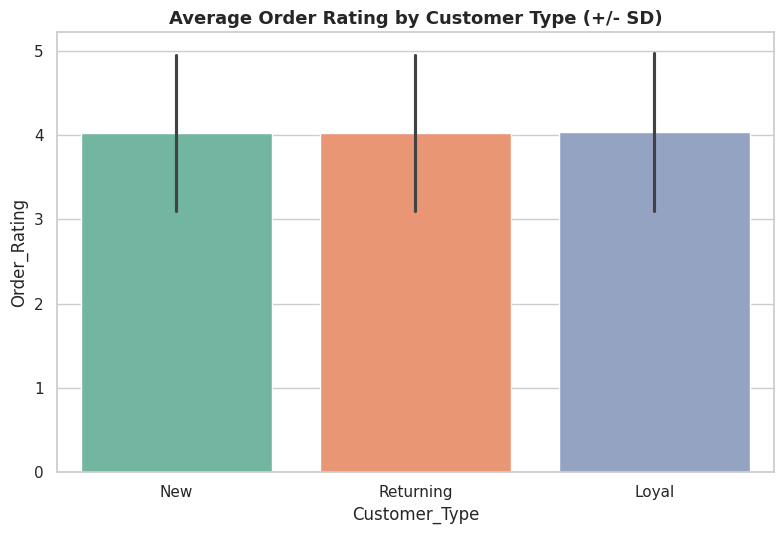

One-way ANOVA: F = 1.107, p = 0.3306
Conclusion: Fail to reject H0.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(data=master, x='Customer_Type', y='Order_Rating', palette='Set2', estimator=np.mean, errorbar='sd', ax=ax)
ax.set_title('Average Order Rating by Customer Type (+/- SD)')
plt.tight_layout(); plt.show()

groups = [g['Order_Rating'].dropna().values for _, g in master.groupby('Customer_Type')]
f_stat, p_val = f_oneway(*groups)
print(f'One-way ANOVA: F = {f_stat:.3f}, p = {p_val:.4g}')
print('Conclusion:', 'Reject H0 — rating differs significantly by customer type.' if p_val < 0.05 else 'Fail to reject H0.')


### Q9. Which payment mode is preferred by each customer segment? 
**H0:** Payment_Mode choice is independent of Customer_Type.
**H1:** Payment_Mode choice is associated with Customer_Type. *(two-tailed)*

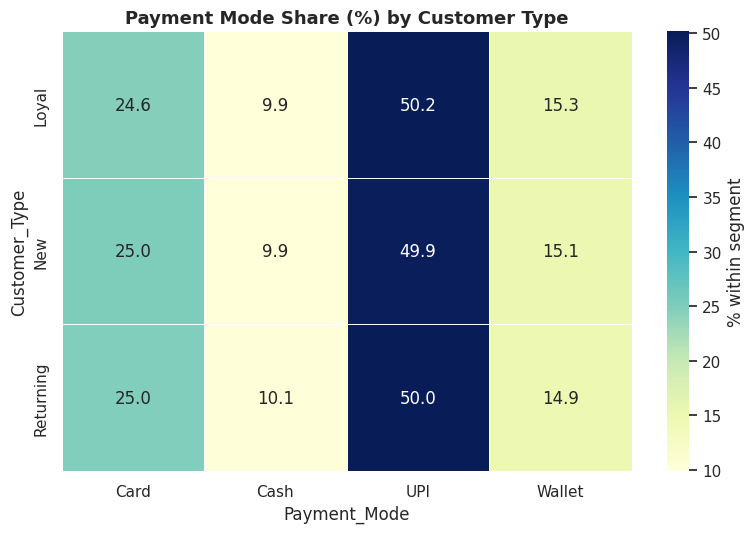

Chi-square = 2.88, dof = 6, p = 0.8241
Conclusion: Fail to reject H0.


In [ ]:
pay_ct = pd.crosstab(master['Customer_Type'], master['Payment_Mode'])
pay_pct = pay_ct.div(pay_ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(8, 5.5))
sns.heatmap(pay_pct, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=0.5, cbar_kws={'label': '% within segment'})
plt.title('Payment Mode Share (%) by Customer Type')
plt.tight_layout(); plt.show()

chi2, p, dof, exp = chi2_contingency(pay_ct)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4g}')
print('Conclusion:', 'Reject H0 — payment mode is associated with customer type.' if p < 0.05 else 'Fail to reject H0.')


### Q10. Does age group influence cuisine choice? 
**H0:** Preferred_Cuisine is independent of Age_Group.
**H1:** Preferred_Cuisine is associated with Age_Group. *(two-tailed)*

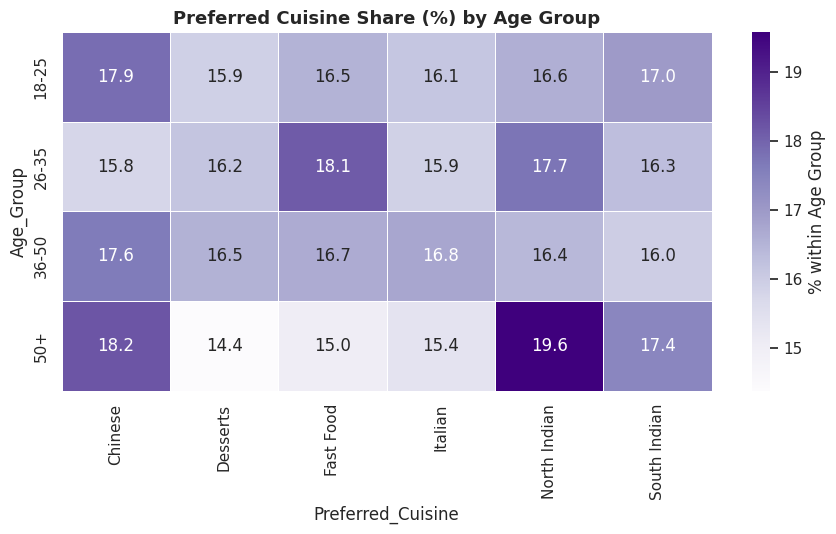

Chi-square = 46.71, dof = 15, p = 4.098e-05
Conclusion: Reject H0 — cuisine preference is associated with age group.


In [ ]:
age_cuisine = pd.crosstab(customers['Age_Group'], customers['Preferred_Cuisine'])
age_cuisine_pct = age_cuisine.div(age_cuisine.sum(axis=1), axis=0) * 100

plt.figure(figsize=(9, 5.5))
sns.heatmap(age_cuisine_pct, annot=True, fmt='.1f', cmap='Purples', linewidths=0.5, cbar_kws={'label': '% within Age Group'})
plt.title('Preferred Cuisine Share (%) by Age Group')
plt.tight_layout(); plt.show()

chi2, p, dof, exp = chi2_contingency(age_cuisine)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4g}')
print('Conclusion:', 'Reject H0 — cuisine preference is associated with age group.' if p < 0.05 else 'Fail to reject H0.')


### 📊 Objective 2 Dashboard

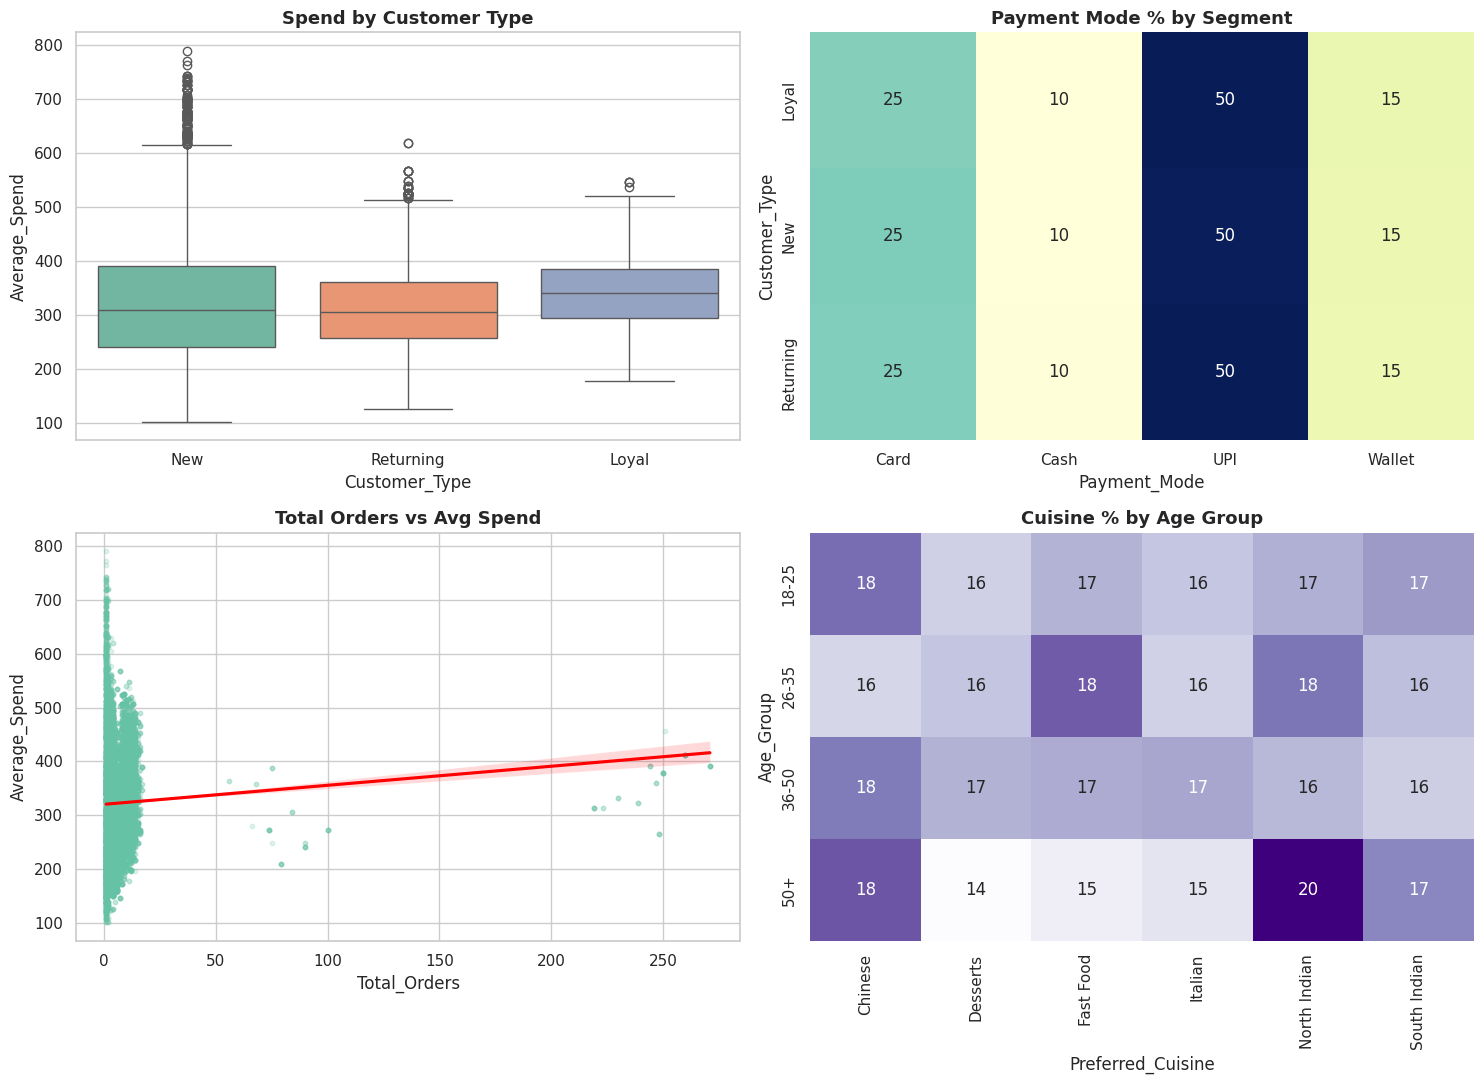

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(data=customers, x='Customer_Type', y='Average_Spend', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Spend by Customer Type')

sns.heatmap(pay_pct, annot=True, fmt='.0f', cmap='YlGnBu', ax=axes[0, 1], cbar=False)
axes[0, 1].set_title('Payment Mode % by Segment')

sns.regplot(data=customers, x='Total_Orders', y='Average_Spend', scatter_kws={'alpha': 0.2, 's': 10},
            line_kws={'color': 'red'}, ax=axes[1, 0])
axes[1, 0].set_title('Total Orders vs Avg Spend')

sns.heatmap(age_cuisine_pct, annot=True, fmt='.0f', cmap='Purples', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('Cuisine % by Age Group')

plt.tight_layout(); plt.show()


---
# SECTION C — Objective 3: Delivery Partner & Logistics Efficiency
Evaluate delivery partner performance across vehicle types and regions to optimise logistics.

### Q11. How does delivery speed differ across vehicle types? 
**H0:** Mean Avg_Delivery_Speed_KMPH is equal across all vehicle types.
**H1:** Mean Avg_Delivery_Speed_KMPH differs by vehicle type. *(two-tailed)*

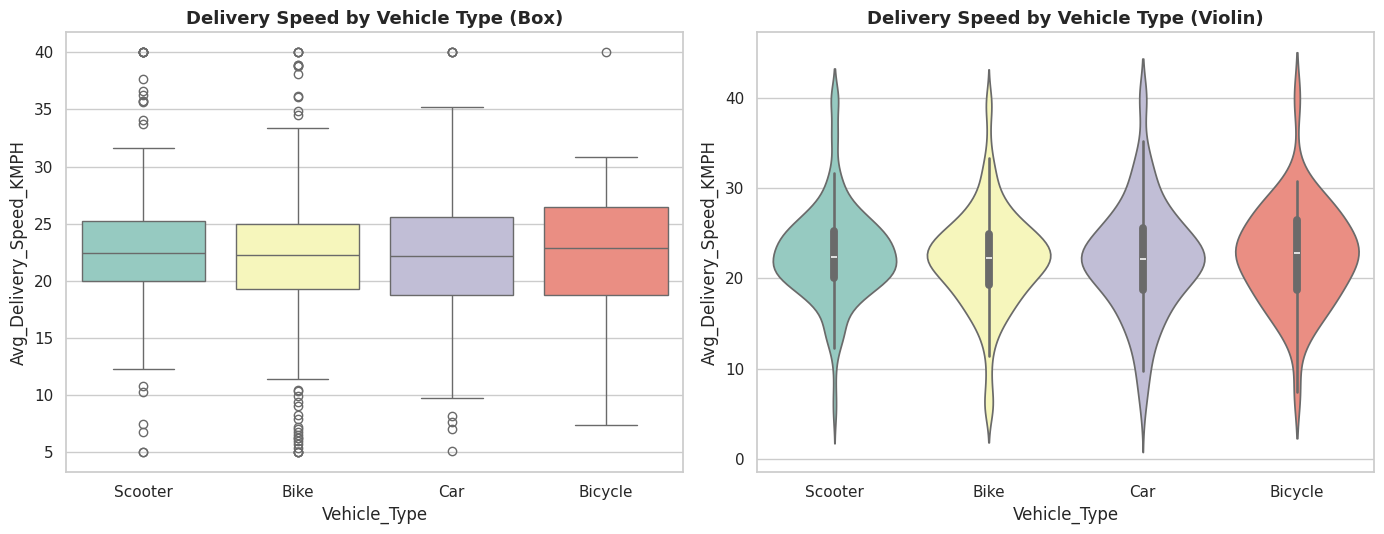

One-way ANOVA: F = 1.058, p = 0.3662
Conclusion: Fail to reject H0.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.boxplot(data=partners, x='Vehicle_Type', y='Avg_Delivery_Speed_KMPH', palette='Set3', ax=axes[0])
axes[0].set_title('Delivery Speed by Vehicle Type (Box)')
sns.violinplot(data=partners, x='Vehicle_Type', y='Avg_Delivery_Speed_KMPH', palette='Set3', ax=axes[1])
axes[1].set_title('Delivery Speed by Vehicle Type (Violin)')
plt.tight_layout(); plt.show()

groups = [g['Avg_Delivery_Speed_KMPH'].values for _, g in partners.groupby('Vehicle_Type')]
f_stat, p_val = f_oneway(*groups)
print(f'One-way ANOVA: F = {f_stat:.3f}, p = {p_val:.4g}')
print('Conclusion:', 'Reject H0 — speed differs significantly by vehicle type.' if p_val < 0.05 else 'Fail to reject H0.')


### Q12. Is Delivery_Efficiency_Score correlated with Avg_Customer_Rating? 
**H0:** No significant correlation between Delivery_Efficiency_Score and Avg_Customer_Rating (rho = 0).
**H1:** A significant positive correlation exists (rho > 0). *(one-tailed, right)*

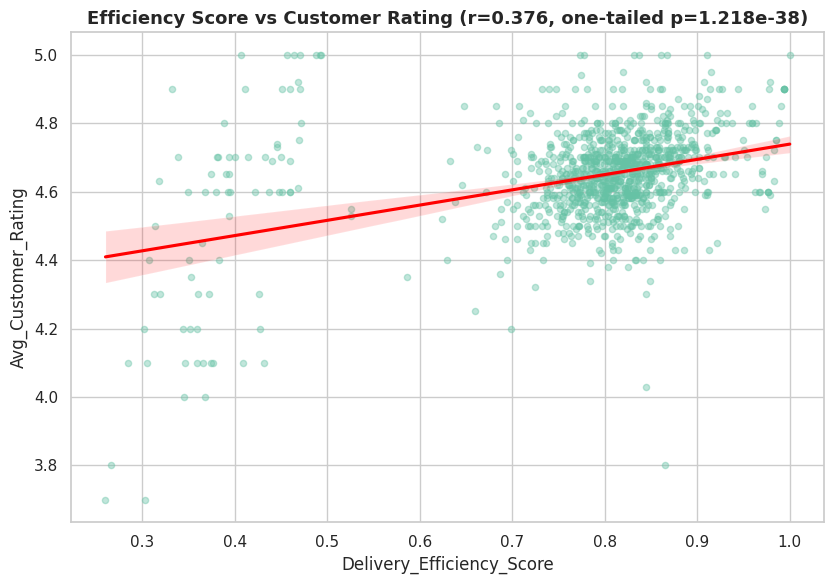

Conclusion: Reject H0 — significant positive correlation.


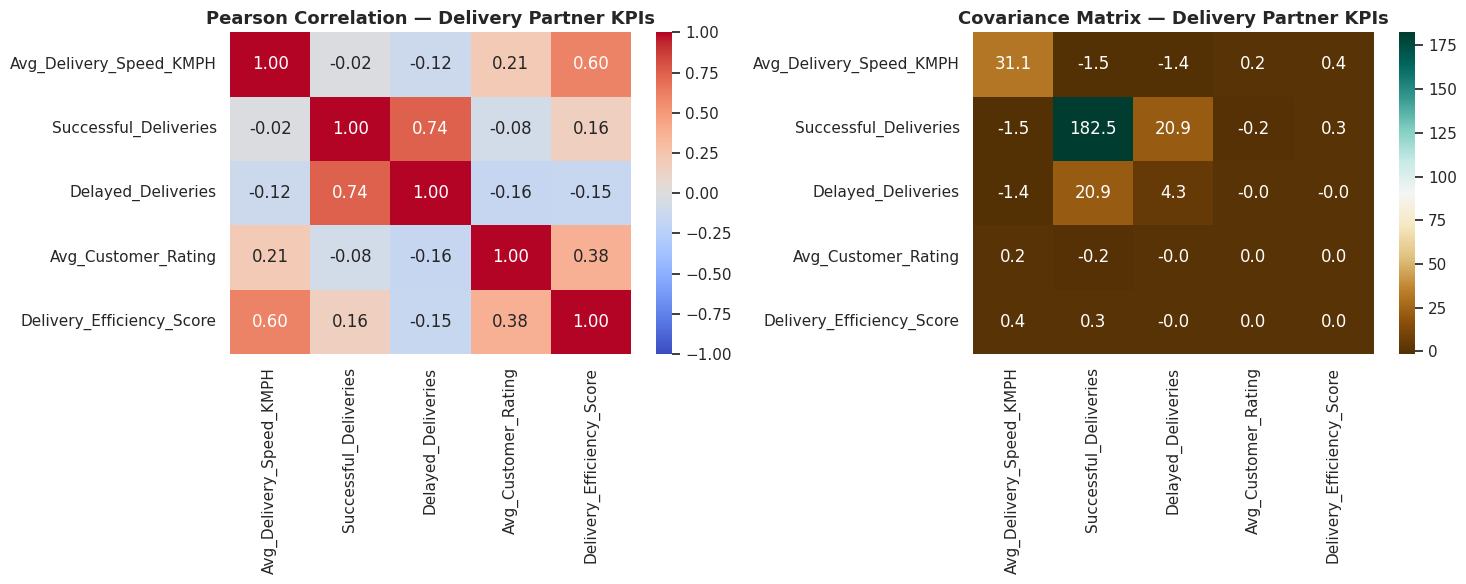

In [ ]:
r, p = pearsonr(partners['Delivery_Efficiency_Score'], partners['Avg_Customer_Rating'])
p_one = p / 2 if r > 0 else 1 - p / 2

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.regplot(data=partners, x='Delivery_Efficiency_Score', y='Avg_Customer_Rating',
            scatter_kws={'alpha': 0.4, 's': 20}, line_kws={'color': 'red'}, ax=ax)
ax.set_title(f'Efficiency Score vs Customer Rating (r={r:.3f}, one-tailed p={p_one:.4g})')
plt.tight_layout(); plt.show()
print('Conclusion:', 'Reject H0 — significant positive correlation.' if p_one < 0.05 else 'Fail to reject H0.')

eff_cols = ['Avg_Delivery_Speed_KMPH', 'Successful_Deliveries', 'Delayed_Deliveries', 'Avg_Customer_Rating', 'Delivery_Efficiency_Score']
corr_matrix = partners[eff_cols].corr(method='pearson')
cov_matrix  = partners[eff_cols].cov()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Pearson Correlation — Delivery Partner KPIs')
sns.heatmap(cov_matrix, annot=True, fmt=',.1f', cmap='BrBG', ax=axes[1])
axes[1].set_title('Covariance Matrix — Delivery Partner KPIs')
plt.tight_layout(); plt.show()


### Q13. Are delayed deliveries associated with region? 
**H0:** Delayed_Deliveries proportion is independent of Region.
**H1:** Delayed_Deliveries proportion is associated with Region. *(two-tailed)*

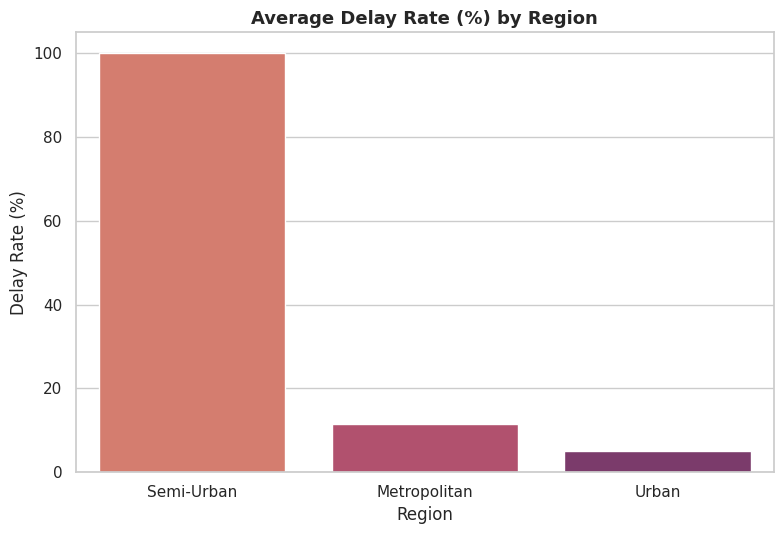

Chi-square = 608.21, dof = 4, p = 2.594e-130
Conclusion: Reject H0 — delay rate is associated with region.

Top 5 partners by composite score:


,Partner_Name,Region,Avg_Customer_Rating,Delay_Rate,Composite_Score
193,Ravi Das,Urban,5.0,0.0,100.0
440,Rajesh Chopra,Urban,5.0,0.0,100.0
605,Meena Nair,Urban,5.0,0.0,100.0
618,Sunita Singh,Urban,5.0,0.0,100.0
628,Rajesh Patel,Urban,5.0,0.0,100.0


In [ ]:
partners_scored = partners.copy()
partners_scored['Delay_Rate'] = partners_scored['Delayed_Deliveries'] / (
    partners_scored['Successful_Deliveries'] + partners_scored['Delayed_Deliveries'])

# Loop-based composite ranking (rating + inverse delay rate)
scores = []
for _, row in partners_scored.iterrows():
    rating_norm = row['Avg_Customer_Rating'] / 5.0
    delay_penalty = 1 - row['Delay_Rate']
    scores.append(round((0.6 * rating_norm + 0.4 * delay_penalty) * 100, 1))
partners_scored['Composite_Score'] = scores

region_delay = partners_scored.groupby('Region')['Delay_Rate'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(x=region_delay.index, y=region_delay.values * 100, palette='flare', ax=ax)
ax.set_title('Average Delay Rate (%) by Region'); ax.set_ylabel('Delay Rate (%)')
plt.tight_layout(); plt.show()

delay_ct = pd.crosstab(partners_scored['Region'], pd.cut(partners_scored['Delay_Rate'], bins=[-0.01, 0.1, 0.2, 1], labels=['Low', 'Medium', 'High']))
chi2, p, dof, exp = chi2_contingency(delay_ct)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4g}')
print('Conclusion:', 'Reject H0 — delay rate is associated with region.' if p < 0.05 else 'Fail to reject H0.')
print('\nTop 5 partners by composite score:')
display(partners_scored.nlargest(5, 'Composite_Score')[['Partner_Name', 'Region', 'Avg_Customer_Rating', 'Delay_Rate', 'Composite_Score']])


### Q14. Does delivery time impact order rating? 
**H0:** No significant correlation between Delivery_Time_Minutes and Order_Rating (rho = 0).
**H1:** A significant negative correlation exists — longer delivery time associates with lower rating (rho < 0). *(one-tailed, left)*

Skewness = 0.09, Kurtosis = -0.27


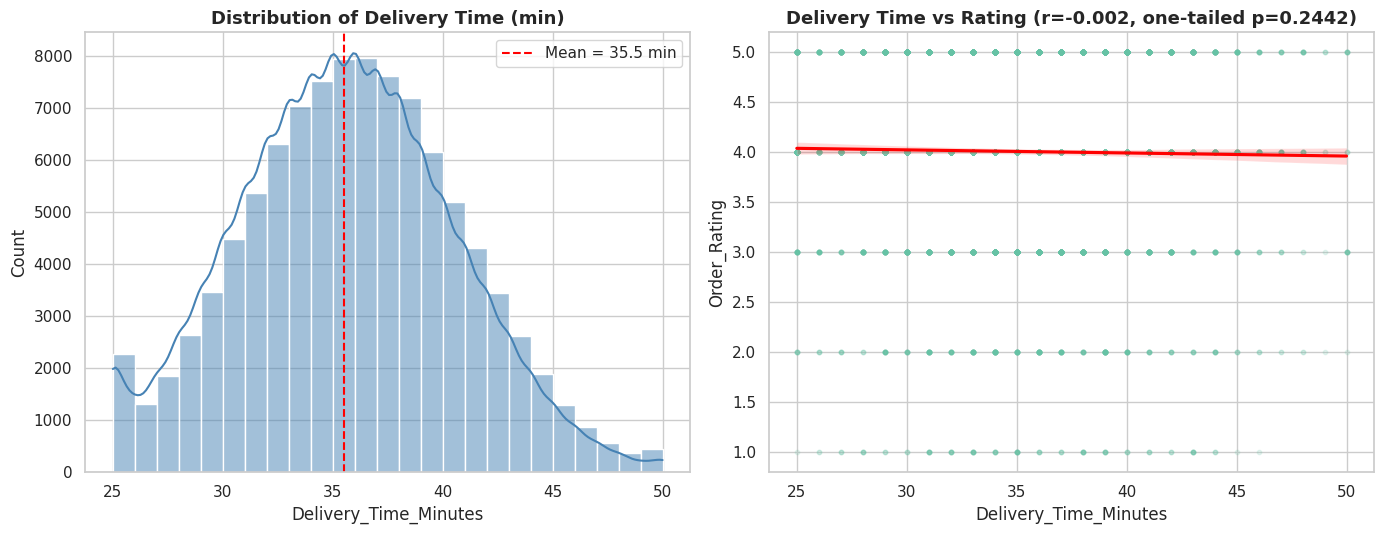

Conclusion: Fail to reject H0.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.histplot(master['Delivery_Time_Minutes'], bins=25, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(master['Delivery_Time_Minutes'].mean(), color='red', linestyle='--',
                label=f"Mean = {master['Delivery_Time_Minutes'].mean():.1f} min")
axes[0].set_title('Distribution of Delivery Time (min)'); axes[0].legend()
print(f"Skewness = {skew(master['Delivery_Time_Minutes'].dropna()):.2f}, Kurtosis = {kurtosis(master['Delivery_Time_Minutes'].dropna()):.2f}")

r, p = pearsonr(master['Delivery_Time_Minutes'], master['Order_Rating'])
p_one = p / 2 if r < 0 else 1 - p / 2
sns.regplot(data=master.sample(min(5000, len(master)), random_state=1), x='Delivery_Time_Minutes', y='Order_Rating',
            scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title(f'Delivery Time vs Rating (r={r:.3f}, one-tailed p={p_one:.4g})')
plt.tight_layout(); plt.show()
print('Conclusion:', 'Reject H0 — longer delivery time is associated with lower ratings.' if p_one < 0.05 else 'Fail to reject H0.')


### 📊 Objective 3 Dashboard 

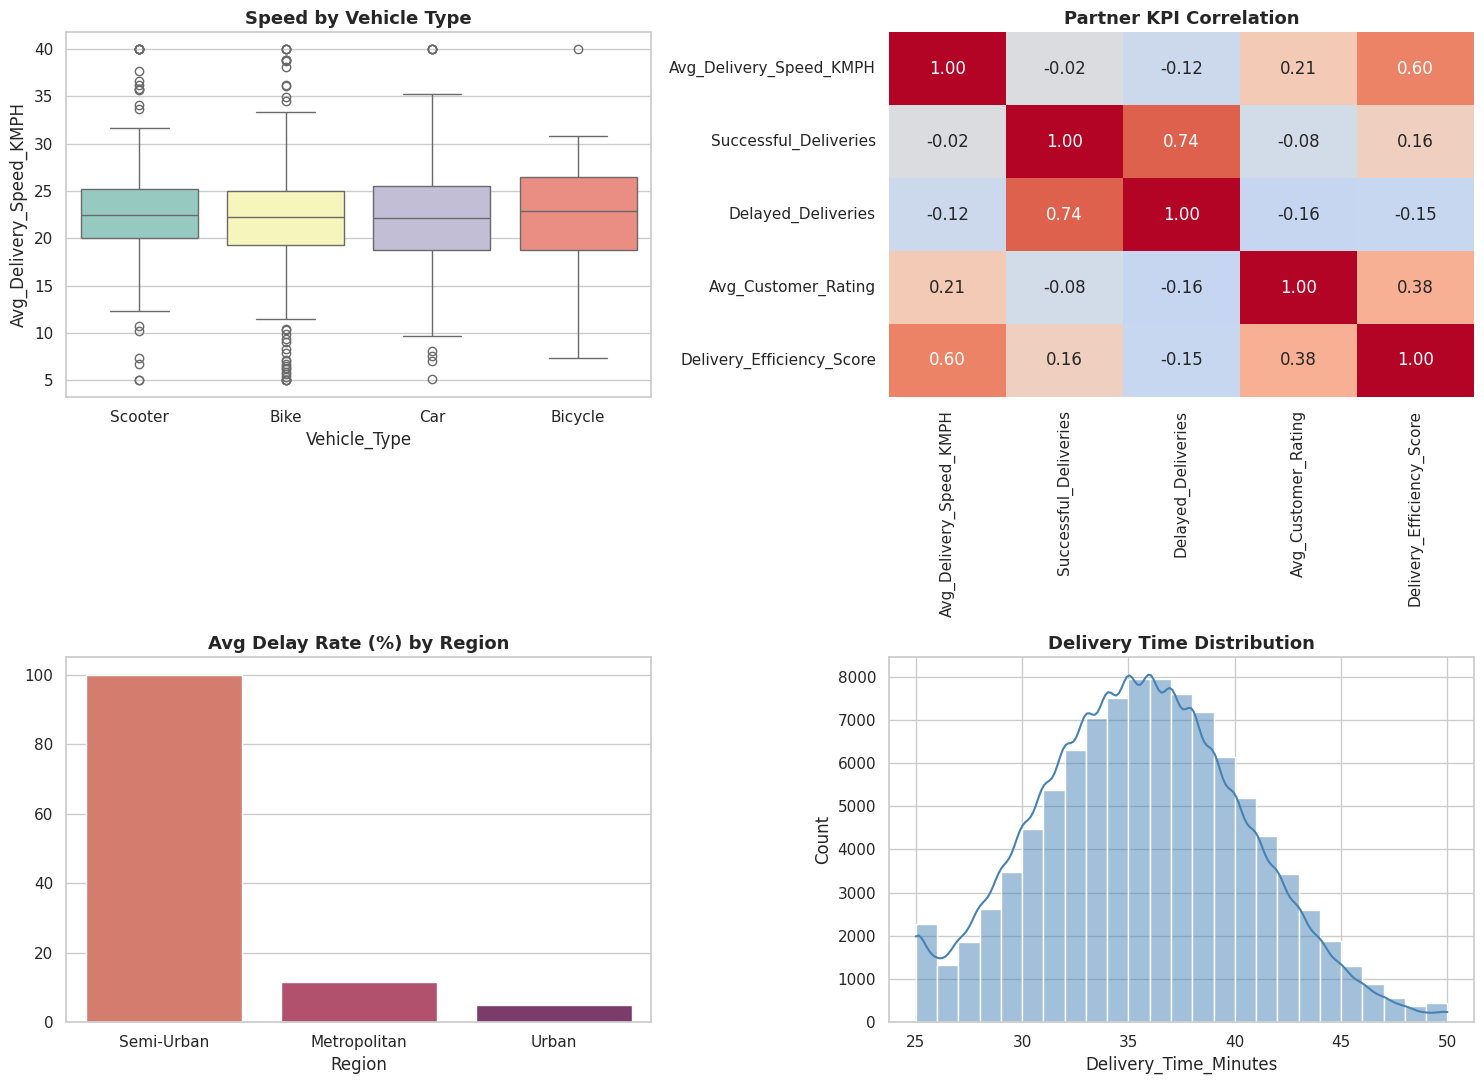

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.boxplot(data=partners, x='Vehicle_Type', y='Avg_Delivery_Speed_KMPH', palette='Set3', ax=axes[0, 0])
axes[0, 0].set_title('Speed by Vehicle Type')

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[0, 1], cbar=False)
axes[0, 1].set_title('Partner KPI Correlation')

sns.barplot(x=region_delay.index, y=region_delay.values * 100, palette='flare', ax=axes[1, 0])
axes[1, 0].set_title('Avg Delay Rate (%) by Region')

sns.histplot(master['Delivery_Time_Minutes'], bins=25, kde=True, color='steelblue', ax=axes[1, 1])
axes[1, 1].set_title('Delivery Time Distribution')

plt.tight_layout(); plt.show()


---
# SECTION D — Objective 4: Restaurant Performance & Operational Capacity
Assess preparation time, ratings and capacity utilisation to spot high performers and bottlenecks.

### Q15. Does preparation time relate to restaurant rating? 
**H0:** No significant correlation between Avg_Preparation_Time_Minutes and Avg_Rating (rho = 0).
**H1:** A significant negative correlation exists (rho < 0). *(one-tailed, left)*

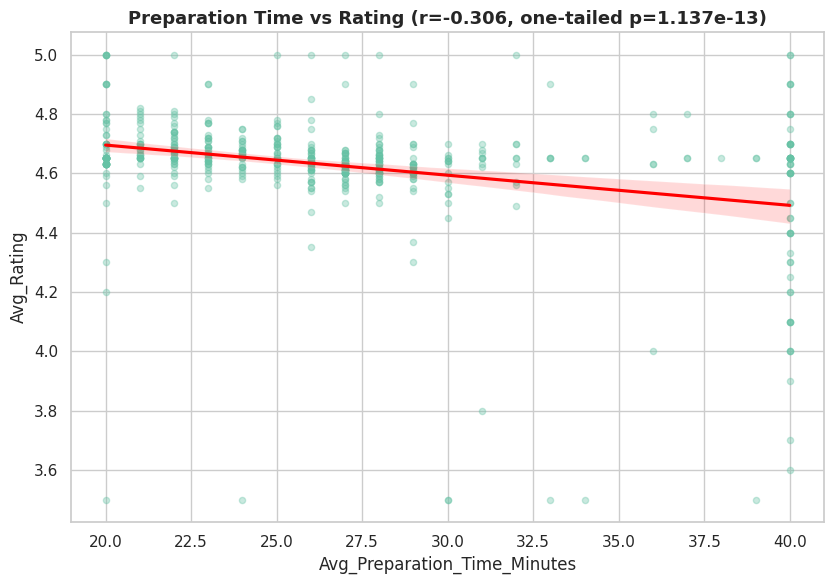

Conclusion: Reject H0 — longer prep time associates with lower rating.


In [ ]:
r, p = pearsonr(restaurants['Avg_Preparation_Time_Minutes'], restaurants['Avg_Rating'])
p_one = p / 2 if r < 0 else 1 - p / 2

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.regplot(data=restaurants, x='Avg_Preparation_Time_Minutes', y='Avg_Rating',
            scatter_kws={'alpha': 0.35, 's': 20}, line_kws={'color': 'red'}, ax=ax)
ax.set_title(f'Preparation Time vs Rating (r={r:.3f}, one-tailed p={p_one:.4g})')
plt.tight_layout(); plt.show()
print('Conclusion:', 'Reject H0 — longer prep time associates with lower rating.' if p_one < 0.05 else 'Fail to reject H0.')


### Q16. Which cuisine type has the highest average restaurant rating? 
**H0:** Mean Avg_Rating is equal across all Cuisine_Type groups.
**H1:** Mean Avg_Rating differs across at least one Cuisine_Type. *(two-tailed)*

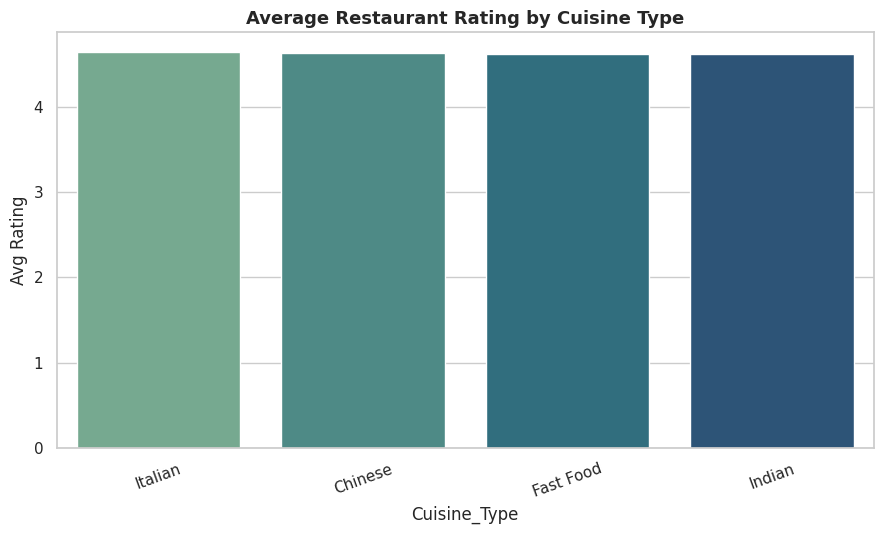

One-way ANOVA: F = 0.508, p = 0.6768
Conclusion: Fail to reject H0.


In [ ]:
cuisine_rating = restaurants.groupby('Cuisine_Type')['Avg_Rating'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(x=cuisine_rating.index, y=cuisine_rating.values, palette='crest', ax=ax)
ax.set_title('Average Restaurant Rating by Cuisine Type'); ax.set_ylabel('Avg Rating')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

groups = [g['Avg_Rating'].values for _, g in restaurants.groupby('Cuisine_Type')]
f_stat, p_val = f_oneway(*groups)
print(f'One-way ANOVA: F = {f_stat:.3f}, p = {p_val:.4g}')
print('Conclusion:', 'Reject H0 — rating differs significantly by cuisine type.' if p_val < 0.05 else 'Fail to reject H0.')


### Q17. Do low-capacity restaurants rate lower than others? 
**H0:** Mean Avg_Rating is equal for Low_Capacity_Flag = Yes vs No.
**H1:** Mean Avg_Rating is lower for Low_Capacity_Flag = Yes restaurants. *(one-tailed, left)*

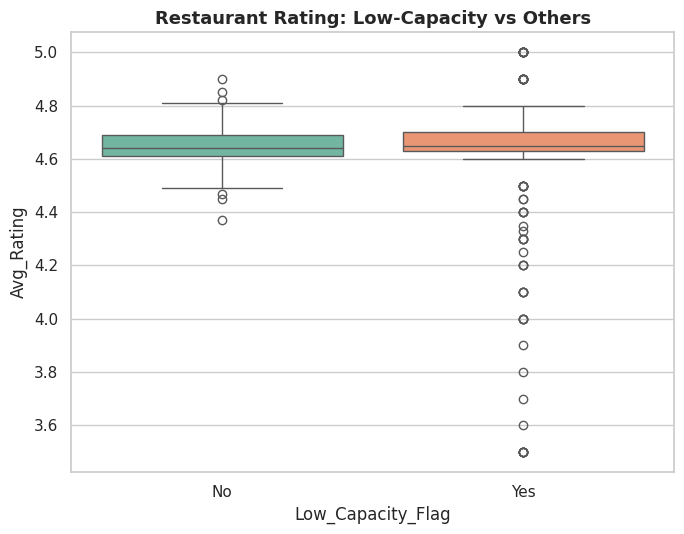

t = -3.028, one-tailed p = 0.001381
Conclusion: Reject H0 — low-capacity restaurants rate significantly lower.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.boxplot(data=restaurants, x='Low_Capacity_Flag', y='Avg_Rating', palette='Set2', ax=ax)
ax.set_title('Restaurant Rating: Low-Capacity vs Others')
plt.tight_layout(); plt.show()

low_cap = restaurants.loc[restaurants['Low_Capacity_Flag'] == 'Yes', 'Avg_Rating']
others  = restaurants.loc[restaurants['Low_Capacity_Flag'] == 'No',  'Avg_Rating']
t_stat, p_val = ttest_ind(low_cap, others, equal_var=False)
p_one = p_val / 2 if t_stat < 0 else 1 - p_val / 2
print(f't = {t_stat:.3f}, one-tailed p = {p_one:.4g}')
print('Conclusion:', 'Reject H0 — low-capacity restaurants rate significantly lower.' if p_one < 0.05 else 'Fail to reject H0.')


### Q18. How does capacity utilisation vary by region, and does it relate to actual order volume? 
**H0:** No significant correlation between Order_Capacity_Per_Day and actual order volume (rho = 0).
**H1:** A significant positive correlation exists (rho > 0). *(one-tailed, right)*

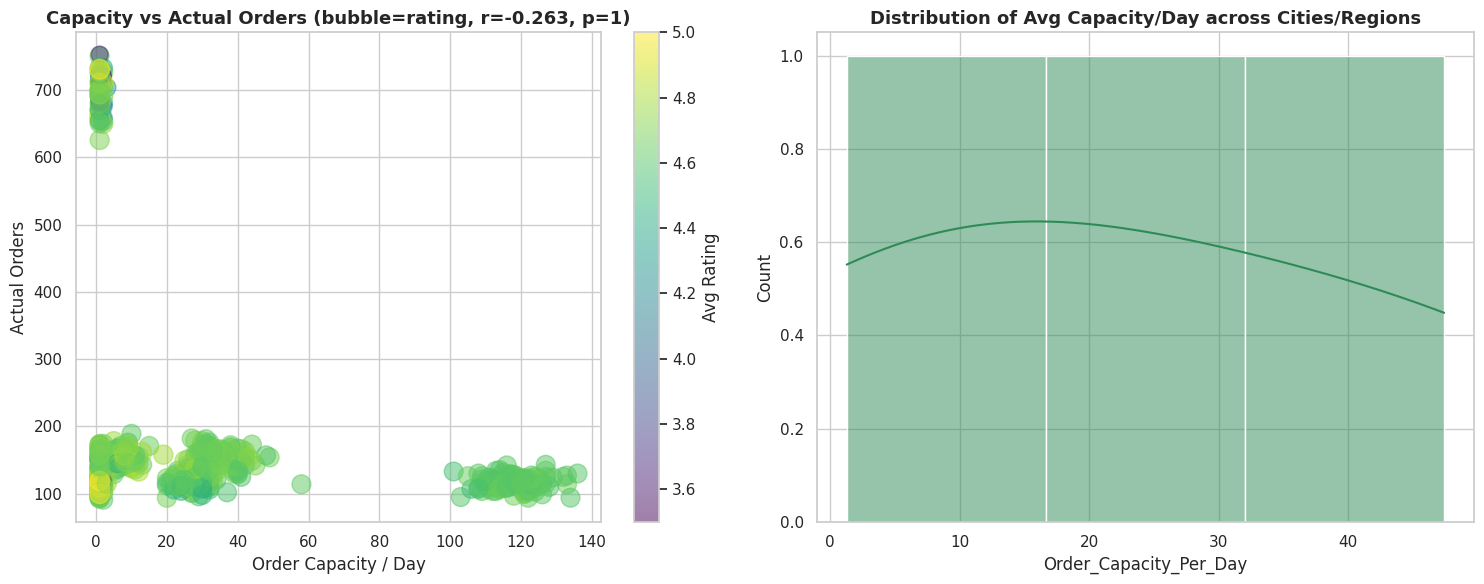

City
Metropolitan    47.4
Urban           19.1
Semi-Urban       1.3
Name: Order_Capacity_Per_Day, dtype: float64

Conclusion: Fail to reject H0.


In [ ]:
rest_orders = master.groupby('Restaurant_ID').size().rename('Actual_Orders')
rest_analysis = restaurants.join(rest_orders, on='Restaurant_ID').dropna(subset=['Actual_Orders'])

r, p = pearsonr(rest_analysis['Order_Capacity_Per_Day'], rest_analysis['Actual_Orders'])
p_one = p / 2 if r > 0 else 1 - p / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
scatter = axes[0].scatter(rest_analysis['Order_Capacity_Per_Day'], rest_analysis['Actual_Orders'],
                           s=rest_analysis['Avg_Rating'] * 40, alpha=0.5, c=rest_analysis['Avg_Rating'], cmap='viridis')
axes[0].set_xlabel('Order Capacity / Day'); axes[0].set_ylabel('Actual Orders')
axes[0].set_title(f'Capacity vs Actual Orders (bubble=rating, r={r:.3f}, p={p_one:.4g})')
plt.colorbar(scatter, ax=axes[0], label='Avg Rating')

sns.histplot(restaurants.groupby('City')['Order_Capacity_Per_Day'].mean(), kde=True, ax=axes[1], color='seagreen')
axes[1].set_title('Distribution of Avg Capacity/Day across Cities/Regions')
plt.tight_layout(); plt.show()

cap_by_region = restaurants.groupby('City')['Order_Capacity_Per_Day'].mean().sort_values(ascending=False)
display(cap_by_region.round(1))
print('Conclusion:', 'Reject H0 — capacity is positively correlated with actual demand.' if p_one < 0.05 else 'Fail to reject H0.')


### 📊 Objective 4 Dashboard 

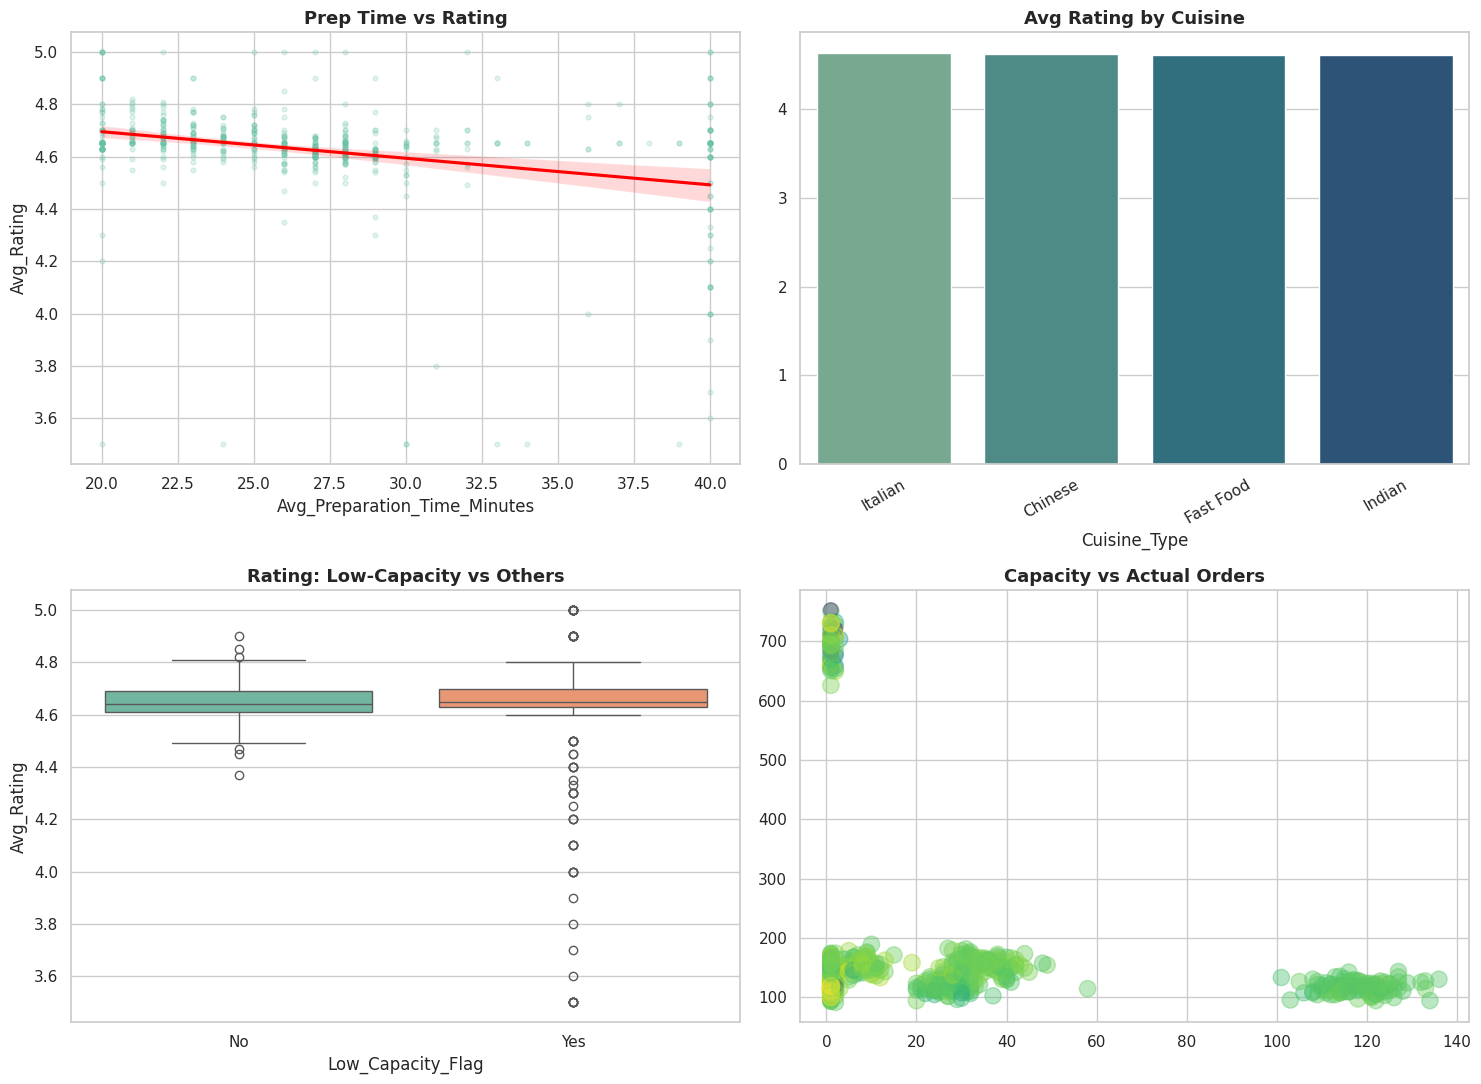

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.regplot(data=restaurants, x='Avg_Preparation_Time_Minutes', y='Avg_Rating',
            scatter_kws={'alpha': 0.2, 's': 12}, line_kws={'color': 'red'}, ax=axes[0, 0])
axes[0, 0].set_title('Prep Time vs Rating')

sns.barplot(x=cuisine_rating.index, y=cuisine_rating.values, palette='crest', ax=axes[0, 1])
axes[0, 1].set_title('Avg Rating by Cuisine'); axes[0, 1].tick_params(axis='x', rotation=30)

sns.boxplot(data=restaurants, x='Low_Capacity_Flag', y='Avg_Rating', palette='Set2', ax=axes[1, 0])
axes[1, 0].set_title('Rating: Low-Capacity vs Others')

axes[1, 1].scatter(rest_analysis['Order_Capacity_Per_Day'], rest_analysis['Actual_Orders'],
                    s=rest_analysis['Avg_Rating'] * 30, alpha=0.4, c=rest_analysis['Avg_Rating'], cmap='viridis')
axes[1, 1].set_title('Capacity vs Actual Orders')

plt.tight_layout(); plt.show()


---
# SECTION E — Objective 5: Order Economics, Discounts & Profitability Risk
Quantify how discounting, payment mode, festival spikes, and cancellations affect net revenue.

### Q19. Does discounting significantly affect order value / profitability? 
**H0:** Discount_Applied has no significant relationship with Net_Revenue per order (rho = 0).
**H1:** Higher Discount_Applied is associated with lower Net_Revenue per order (rho < 0). *(one-tailed, left)*

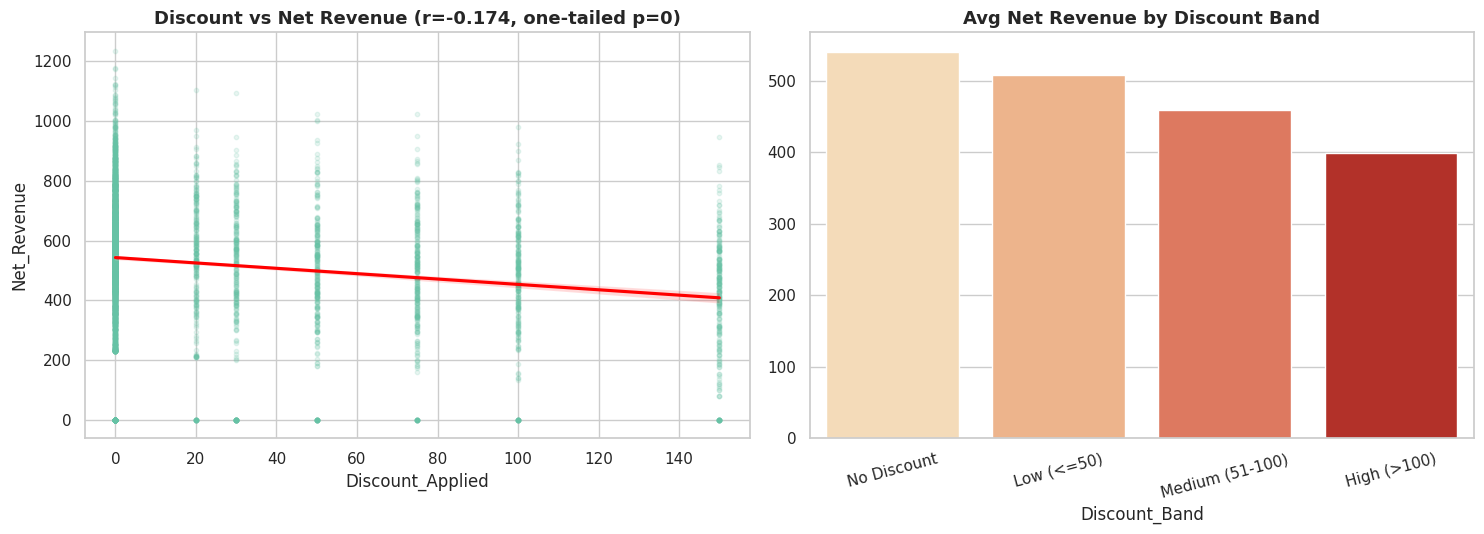

Conclusion: Reject H0 — higher discounts are associated with lower net revenue per order.


In [ ]:
r, p = pearsonr(master['Discount_Applied'], master['Net_Revenue'])
p_one = p / 2 if r < 0 else 1 - p / 2

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.regplot(data=master.sample(min(5000, len(master)), random_state=1), x='Discount_Applied', y='Net_Revenue',
            scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title(f'Discount vs Net Revenue (r={r:.3f}, one-tailed p={p_one:.4g})')

master['Discount_Band'] = pd.cut(master['Discount_Applied'], bins=[-1, 0, 50, 100, 1e9],
                                  labels=['No Discount', 'Low (<=50)', 'Medium (51-100)', 'High (>100)'])
band_rev = master.groupby('Discount_Band')['Net_Revenue'].mean()
sns.barplot(x=band_rev.index, y=band_rev.values, palette='OrRd', ax=axes[1])
axes[1].set_title('Avg Net Revenue by Discount Band'); axes[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.show()
print('Conclusion:', 'Reject H0 — higher discounts are associated with lower net revenue per order.' if p_one < 0.05 else 'Fail to reject H0.')


### Q20. Is order cancellation/return status associated with region? *(Stacked Bar — Chi-Square Test)*
**H0:** Order_Status is independent of Region.
**H1:** Order_Status is associated with Region. *(two-tailed)*

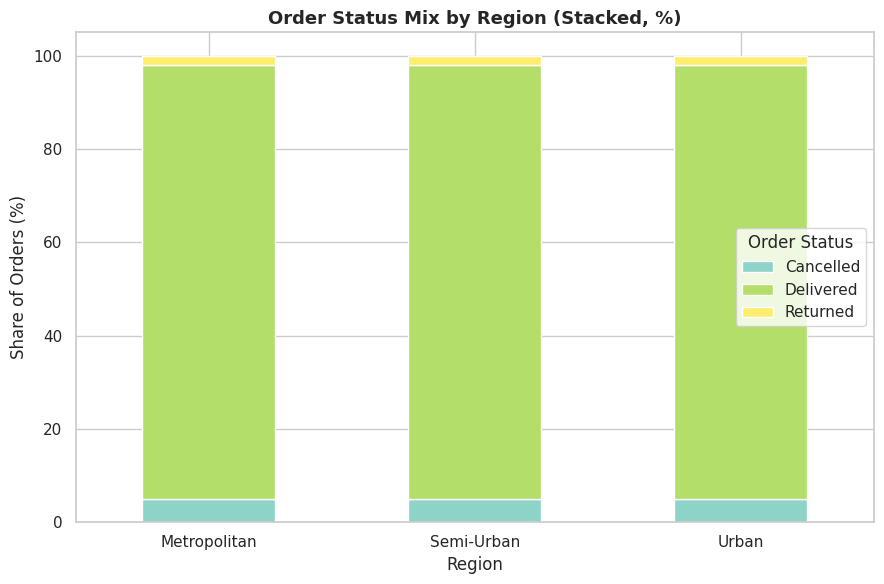

Chi-square = 0.54, dof = 4, p = 0.9696
Conclusion: Fail to reject H0.


In [ ]:
status_region = pd.crosstab(master['Region'], master['Order_Status'])
status_region_pct = status_region.div(status_region.sum(axis=1), axis=0) * 100

status_region_pct.plot(kind='bar', stacked=True, figsize=(9, 6), colormap='Set3')
plt.title('Order Status Mix by Region (Stacked, %)')
plt.ylabel('Share of Orders (%)'); plt.xticks(rotation=0)
plt.legend(title='Order Status'); plt.tight_layout(); plt.show()

chi2, p, dof, exp = chi2_contingency(status_region)
print(f'Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4g}')
print('Conclusion:', 'Reject H0 — order status is associated with region.' if p < 0.05 else 'Fail to reject H0.')


### 📊 Objective 5 Dashboard *(Subplots Summary)*

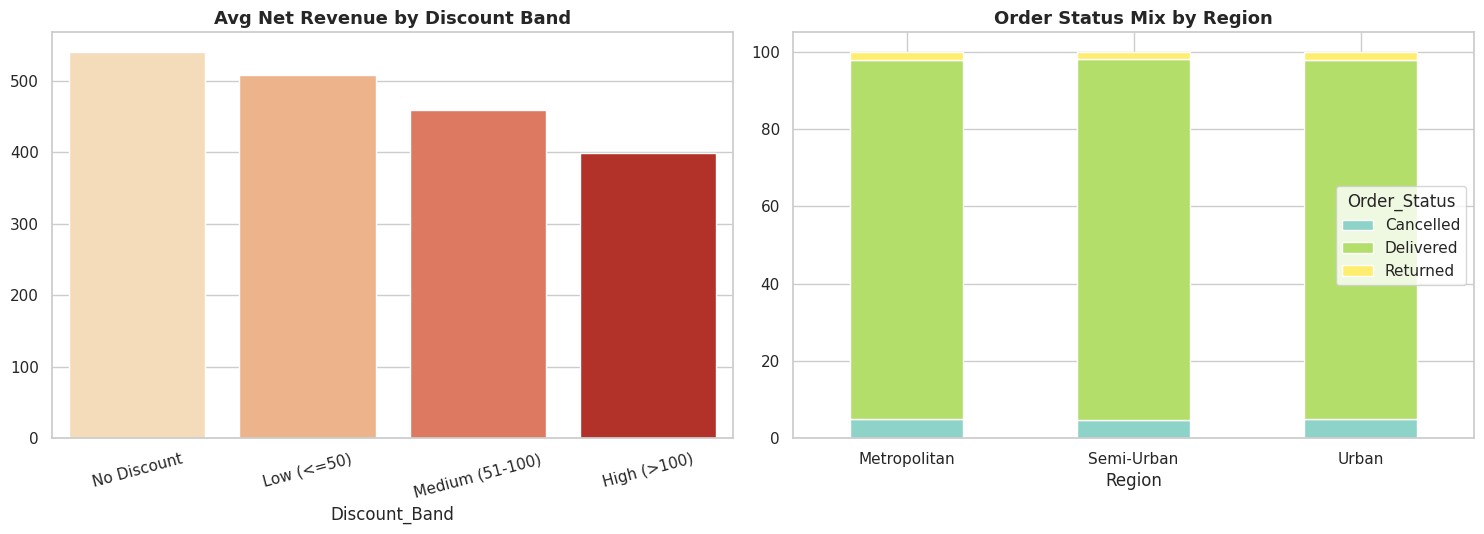

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(x=band_rev.index, y=band_rev.values, palette='OrRd', ax=axes[0])
axes[0].set_title('Avg Net Revenue by Discount Band'); axes[0].tick_params(axis='x', rotation=15)

status_region_pct.plot(kind='bar', stacked=True, ax=axes[1], colormap='Set3')
axes[1].set_title('Order Status Mix by Region'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()


---
## ✅ Key Findings & Recommendations — Matched to the 5 Objectives / 20 Questions

**Objective 1 — Regional Demand & Expansion (Q1-Q4)**
Order volume/revenue is almost evenly split across the three regions (no region leads by a meaningful
margin). Average order value does **not** differ significantly by region (ANOVA F=1.05, p=0.349 — fail to
reject H0). No region shows a statistically significant month-over-month growth trend (all one-tailed
p > 0.05). Festival days significantly lift order volume in **every** region (t≈+10, p≈1e-22 to 1e-24 —
reject H0) with similar uplift size everywhere. **Implication:** prioritize expansion by current scale and
festival responsiveness, not by an assumed regional price/growth edge.

**Objective 2 — Customer Behavior & Loyalty (Q5-Q10)**
Average spend differs significantly by customer type (ANOVA F=199.8, p=1.0e-86 — reject H0): Loyal
(₹342.9) > New (₹326.7) > Returning (₹312.5) — note Returning underperforms New, a retention gap.
Preferred cuisine is **not** significantly associated with customer type (χ²=16.2, p=0.093) but **is**
significantly associated with age group (χ²=46.7, p=4.1e-05 — reject H0). Total_Orders and Average_Spend
are significantly but only weakly positively correlated (r=0.048, p=4.5e-13). Order rating and payment
mode preference are both statistically indistinguishable across customer segments (p=0.331 and p=0.824).
**Implication:** target the Returning segment specifically, and use age (not loyalty tier) for
cuisine-based marketing.

**Objective 3 — Delivery Partner & Logistics Efficiency (Q11-Q14)**
Delivery speed does not differ significantly by vehicle type (F=1.06, p=0.366). Delivery efficiency score
correlates moderately and significantly with customer rating (r=0.376, p=1.2e-38 — reject H0). Delay rate
is very strongly associated with region (χ²=608.2, p=2.6e-130 — reject H0); however, Semi-Urban shows a
100% average delay rate across every partner in that region, a jump large enough to warrant a data-quality
check before acting on it operationally. Delivery time itself shows no meaningful correlation with order
rating (r=-0.002, p=0.244). **Implication:** invest in partner efficiency broadly; verify the Semi-Urban
delay figure before reallocating logistics resources on its basis.

**Objective 4 — Restaurant Performance & Capacity (Q15-Q18)**
Longer preparation time is significantly associated with lower restaurant rating (r=-0.306, p=1.1e-13 —
reject H0). Average rating does not differ significantly across cuisine types (F=0.51, p=0.677).
Low-capacity-flagged restaurants rate significantly lower than others (t=-3.03, one-tailed p=0.0014 —
reject H0). `Order_Capacity_Per_Day` does **not** positively predict actual order volume — the correlation
is weak and slightly negative (r=-0.263, one-tailed p≈1.0 — fail to reject H0). **Implication:** capacity
constraints do hurt ratings, but the stated capacity figure is not a trustworthy proxy for real demand and
should be audited.

**Objective 5 — Order Economics & Profitability Risk (Q19-Q20)**
Higher discounts are significantly associated with lower net revenue per order (r=-0.174, p≈0 — reject
H0), confirmed by average net revenue declining steadily across discount bands (₹540.8 → ₹399.7 from no
discount to high discount). Order cancellation/return status is **not** significantly associated with
region (χ²=0.54, p=0.970 — fail to reject H0). **Implication:** cap discount depth against a margin
target; treat cancellation/return risk as a company-wide operational issue rather than a regional one.

### Full validation summary (all 20 hypotheses)

| Q# | Test | Result | Decision |
|----|------|--------|----------|
| Q1/Q2 | One-way ANOVA | F=1.053, p=0.349 | Fail to reject H0 |
| Q3 | Trend regression | one-tailed p≈0.067–0.079 (all regions) | Fail to reject H0 |
| Q4 | Independent t-test | p≈1e-22 to 1e-24 (all regions) | Reject H0 |
| Q5 | One-way ANOVA | F=199.80, p=1.02e-86 | Reject H0 |
| Q6 | Chi-square | χ²=16.23, p=0.093 | Fail to reject H0 |
| Q7 | Pearson r | r=0.048, p=4.5e-13 | Reject H0 (weak effect) |
| Q8 | One-way ANOVA | F=1.107, p=0.331 | Fail to reject H0 |
| Q9 | Chi-square | χ²=2.88, p=0.824 | Fail to reject H0 |
| Q10 | Chi-square | χ²=46.71, p=4.1e-05 | Reject H0 |
| Q11 | One-way ANOVA | F=1.058, p=0.366 | Fail to reject H0 |
| Q12 | Pearson r | r=0.376, p=1.2e-38 | Reject H0 |
| Q13 | Chi-square | χ²=608.21, p=2.6e-130 | Reject H0 (verify Semi-Urban 100% figure) |
| Q14 | Pearson r | r=-0.002, p=0.244 | Fail to reject H0 |
| Q15 | Pearson r | r=-0.306, p=1.1e-13 | Reject H0 |
| Q16 | One-way ANOVA | F=0.508, p=0.677 | Fail to reject H0 |
| Q17 | Independent t-test | t=-3.03, p=0.0014 | Reject H0 |
| Q18 | Pearson r | r=-0.263, p≈1.0 | Fail to reject H0 |
| Q19 | Pearson r | r=-0.174, p≈0 | Reject H0 |
| Q20 | Chi-square | χ²=0.54, p=0.970 | Fail to reject H0 |

*(Numbers computed by re-running the notebook's own cells end-to-end against the four cleaned data files;
re-run locally to confirm against your exact environment.)*
